# Lecture 24 - Agentic AI

[![View notebook on Github](https://img.shields.io/static/v1.svg?logo=github&label=Repo&message=View%20On%20Github&color=lightgrey)](https://github.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/blob/main/Lectures/Theme_3-Model_Engineering/Lecture_24-Agentic_AI/Lecture_24-Agentic_AI.ipynb)
[![Open In Collab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/avakanski/Fall-2026-Applied-Data-Science-with-Python/blob/main/Lectures/Theme_3-Model_Engineering/Lecture_24-Agentic_AI/Lecture_24-Agentic_AI.ipynb)
[![View on Website](https://img.shields.io/static/v1.svg?logo=quarto&label=Web&message=View%20on%20Website&color=blue)](https://avakanski.github.io/Fall-2026-Applied-Data-Science-with-Python/Lectures/Theme_3-Model_Engineering/Lecture_24-Agentic_AI/Lecture_24-Agentic_AI.html)

<a id='top'></a>

- [24.1 Introduction to Agentic AI](#24.1-introduction-to-agentic-ai)
    - [24.1.1 Agentic Architectures](#24.1.1-agentic-architectures)
    - [24.1.2 Agentic Frameworks](#24.1.2-agentic-frameworks)
- [24.2 Tool Calling Agents](#24.2-tool-calling-agents)
- [24.3 Coding Agents](#24.3-coding-agents)
    - [24.3.1 Default Toolbox](#24.3.1-default-toolbox)
- [24.4 Creating Custom Tools](#24.4-creating-custom-tools)
    - [24.4.1 Defining a Tool using the tool Decorator](#24.4.1-defining-a-tool-using-the-tool-decorator)
    - [24.4.2 Defining a Tool as a Python Class](#24.4.2-defining-a-tool-as-a-python-class)
    - [24.4.3 Sharing and Importing Tools](#24.4.3-sharing-and-importing-tools)
- [24.5 RAG Agents](#24.5-rag-agents)
- [24.6 Multi-Agent Systems](#24.6-multi-agent-systems)
- [24.7 Vision Agents](#24.7-vision-agents)
- [24.8 Applications](#24.8-applications)
- [24.9 Challenges and Risks in Agentic AI](#24.9-challenges-and-risks-in-agentic-ai)
- [Appendix: Additional Multi-Agent Systems](#appendix:-additional-multi-agent-systems)
- [References](#references)

<a id="24.1-introduction-to-agentic-ai"></a>

## 24.1 Introduction to Agentic AI

Today, the AI field is progressing at an accelerating pace, characterized by a shift from Generative AI to Agentic AI.

**Generative AI** models (such as LLMs) can write text, create images, generate code, and more. However, these models are mostly reactive, as they wait for a prompt from the user, and afterwards they produce a response.

**Agentic AI** transforms LLMs from passive, reactive knowledge systems into active systems capable of taking initiative and performing actions. Instead of just answering questions, an AI agent can plan and act.  For example, when given the task "Plan a marketing campaign for next quarter," an agent can break the task into smaller steps, use external tools like web search or databases, check the results, and iterate until the task is completed.

An **agent** is not simply an LLM that outputs text, but it is a computational entity capable of reasoning, planning, and executing actions to achieve a goal. Differently from a standard LLM response generation, which typically involves a single pass to produce an output, an agent operates within a continuous control loop. The loop involves observing the environment, reasoning about the current state, formulating a plan, executing actions, and using the output of those actions to refine the next steps.

The transition to Agentic AI provides benefits, but also introduces significant complexity compared to standard LLM pipelines. Agents must manage internal state, handle execution errors, and interact with external interfaces such as APIs, databases, and web browsers.

<a id="24.1.1-agentic-architectures"></a>

### 24.1.1 Agentic Architectures

The dominant architectures that form the foundation of many modern AI agent systems are ReAct, Plan-and-Execute, and Reflexion.

**ReAct (Reason + Act)** is the most common pattern and combines the reason and act modes in one continuous loop, consisting of:

1. *Thought*: The agent analyzes the current step and explains its reasoning steps. Example: "I need to check the weather in Chicago before recommending clothing."
2. *Action*: The agent performs a tool call, such as a web search. Example: "Get the weather for Chicago".
3. *Observation*: The tool returns the results. Example: "Rain, 52°F."
4. *Update*: The agent uses the new information and continues the cycle. Example: "Since it's raining, I should suggest a raincoat."

This continuous loop helps the agent correct itself and produce more reliable responses. If an Action fails (for example, if a tool returns an error), the agent notices the failure in the Observation step and can adjust its plan in the next Thought step, instead of producing an incorrect answer.

**Plan-and-Execute** separates the task into two stages: first the agent creates a multi-step plan, and then it executes each step, often using smaller or specialized models. This approach is efficient for structured tasks and is widely used in production systems where speed and cost matter.

**Reflexion** enables an agent to critique its own outputs, learn from mistakes, and iteratively improve its reasoning. It is especially useful for tasks where accuracy is critical, as the agent builds a self-feedback loop to refine future attempts.

Modern agent frameworks often combine these architectures for better performance. E.g., ReAct + Reflexion agents act step-by-step and self-correct across attempts, or Plan-and-Execute + ReAct agents can first generate a plan but use ReAct loops to execute complex steps. As well as, high-end autonomous agents can combine all three architectures.

<a id="24.1.2-agentic-frameworks"></a>

### 24.1.2 Agentic Frameworks

Several Agentic AI frameworks have become widely adopted in both industry and research. The commonly used frameworks include:

- **LangGraph/LangChain (LangChain)**: LangGraph offers a state-machine and graph-based architecture that allows developers to design agents with explicit control over each step of execution. It is one of the most commonly used agentic frameworks at the present time, and it is a go-to choice for complex agents requiring retries, branching logic, memory, and tool orchestration.
- **Smolagents (Hugging Face)**: Smolagents is a lightweight, open-source framework designed for transparency and ease of use. It is widely used in open-source communities to build ReAct-style agents that can run on open models like LLaMA, Qwen, and Mistral.
- **AutoGen (Microsoft)**: AutoGen is now part of Microsoft's agent framework, and it excels at conversational multi-agent patterns. It allows multiple agents to collaborate with each other and with humans using structured conversation loops. It is frequently used in research and prototyping to build multi-agent systems capable of solving problems collectively.
- **CrewAI (CrewAI)**: CrewAI organizes agents into specialized roles (a "crew") that cooperate to complete tasks through coordinated workflows. It allows users to define agents with specific personas and responsibilities, assign them tasks, and let them collaborate. It is popular for automating research and data workflows through teams of domain-specific agents.
- **LlamaIndex (LlamaIndex)**: LlamaIndex provides a flexible framework for building RAG and tool-using agents, with a focus on data connectors, indexing, and structured reasoning. It is used for constructing agents that operate over private data and employ query engines for step-by-step reasoning.
- **OpenAI Agents SDK (OpenAI)**: The Agents SDK allows building autonomous AI workflows on top of the OpenAI API. It supports tool integration, structured planning, memory, handoffs between agents, and multi-step task execution, and it is a widely used production agent framework.
- **Claude Agent SDK (Anthropic)**: The Claude Agent SDK provides the agent loop, tool use, context management, and permission controls that are used by Claude Code, so that developers can build their own agents on the same components. Anthropic has also described a set of *workflow patterns* for building reliable agentic systems, which we will study in the next lecture.

In this lecture, we will introduce Agentic AI through the `smolagents` framework, developed by Hugging Face. The properties of being lightweight, open-source, and easy to use are the main reasons for selecting it for this lecture. We will cover LangGraph/LangChain, AutoGen, and CrewAI in the next lecture.

<a id="24.2-tool-calling-agents"></a>

## 24.2 Tool Calling Agents

The two main ways to build an agent in `smolagents` are Tool Calling Agents and Coding Agents.

A **Tool Calling Agent** is the "standard" approach, where the agent selects a tool and provides inputs in a structured format (e.g., JSON). This approach for building agents is reliable for simple tasks but less flexible for complex reasoning.

Let's work through an example where we will build a simple agent that can search the web to answer a user's question. For this purpose, we will use the `DuckDuckGo` web search tool available in the `smolagents` framework.

To build an agent, we need at least two elements:

- `tools`: a list of tools the agent has access to.
- `model`: an LLM that serves as the engine of the agent.

For the **tool**, we will use `DuckDuckGo` for this example. In general,  tools can be downloaded from the Hugging Face Hub or other frameworks. We can also create custom tools by writing our own functions. This will be explained in a later section.

For the **model**, the framework provides distinct classes to connect to different LLM providers:

- `InferenceClientModel` is the default class, which connects to Hugging Face's serverless inference service, allowing developers to run models hosted on the Hugging Face Hub. I.e., the agent runs on Hugging Face infrastructure, and no local GPU is required. However, only a small number of free tokens are offered per month for experimentation and prototyping. Beyond that quota, usage becomes pay-as-you-go under provider rates.
- `HfApiModel` class also uses Hugging Face's free inference API to give access to open-source LLMs and other models without local hosting. Still, availability and cost depend on the compute requirements of the chosen model, and for medium to large LLMs or frequent use, you may quickly exhaust free credits and need to pay for additional usage. The `HfAPIModel` interface is older legacy method for running inference on Hugging Face from older `huggingface_hub` versions, while `InferenceClientModel` is the modern, fully supported API that provides consistent outputs, streaming, and model support.
- `LiteLLMModel` class allows users to choose from a list of 100+ proprietary LLM providers, like OpenAI, Anthropic, or Azure. Agents can be powered by models like GPT-4o or Claude 4.5 Sonnet, which often have superior performance for highly complex tasks. Using proprietary LLMs requires providing the API key, and there are costs associated with using these models.

**Setup: Libraries and Imports**

To begin using `smolagents`, we need to install the library. Since we will use  `DuckDuckGo` and `Tavily` for web searches, we also install the corresponding `ddgs` and `tavily-python` packages. The libraries `markdownify` and `requests` will be needed later for a tool to visit webpages.

In [1]:
!pip install -q smolagents ddgs tavily-python markdownify requests

The following cell imports `ToolCallingAgent` and `DuckDuckGoSearchTool` from `smolagents`, and from the `models` module it imports `InferenceClientModel`.

To use the Hugging Face API, we need to provide a Hugging Face access token. In my case, I saved the token in Google Colab Secrets which is located in the left panel in Colab (look for the key icon). Importing `userdata` from Google Colab in the cell below will be used later by Colab to automatically load the token stored in the Secrets tab.

In [2]:
from smolagents import ToolCallingAgent, DuckDuckGoSearchTool
from smolagents.models import InferenceClientModel
from google.colab import userdata

**Loading the Hugging Face Token and Initializing the Model**

This cell first retrieves the Hugging Face token from Colab Secrets.  

Next, we create the client and select `Llama-3.3-70B-Instruct` as the LLM for the agent. The token is used for authentication when accessing the model through the Hugging Face API.

In [3]:
# Get the Hugging Face token
token = userdata.get('HF_TOKEN')

# Create a client model
model = InferenceClientModel(model_id="meta-llama/Llama-3.3-70B-Instruct", token=token)

**Web Search Tool Setup**

The next cell creates an AI agent equipped with a web search tool. Tool calling agents require a list of tools they are allowed to use. Here, we provide a single tool `DuckDuckGoSearchTool()`, configured to return up to 3 search results with the argument `max_results=3`. The argument `rate_limit=0.5` allows at most one query every two seconds, which reduces the chance that DuckDuckGo blocks the searches, as explained below. We also pass the LLM `model` that we set up earlier, and the argument `max_steps`, which limits how many reasoning steps the agent can take before it stops.

This constructs an agent capable of reasoning, generating actions, and retrieving information from the internet via `DuckDuckGo`.

In [4]:
# Create a simple agent with a web search tool
agent = ToolCallingAgent(tools=[DuckDuckGoSearchTool(max_results=3, rate_limit=0.5)],
                         model=model, max_steps=5)

**Running the Agent**

The following cell runs the agent on a specific question. Calling `agent.run(...)` passes the query to the agent, the agent uses the `Llama-3.3-70B-Instruct` LLM to reason about the task, the LLM calls the `DuckDuckGo` search tool to look up information, and the final answer is displayed. Please note that `DuckDuckGo` does not require an API key, but it blocks automated traffic and after several queries it stops returning search results. For this reason `DuckDuckGoSearchTool` limits the requests to one query per second by default. Since an agent can send many searches for a single task, and since all Google Colab users share the same outgoing IP addresses, the searches often stop working during a class. For this reason, later in the lecture we will switch to the Tavily Web Search tool.

In [5]:
# Run the agent
agent.run("What is the capital of France and what is it known for?")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ What is the capital of France and what is it known for?                                                         │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'web_search' with arguments: {'query': 'capital of France'}                                       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Observations: ## Search Results

|Capital of France](https://en.wikipedia.org/wiki/Capital_of_France)
This is a chronological list of capitals of France. The capital of France has been Paris since its liberation in 
1944.

|Capital Gains Tax on Works of Art in 
France](https://grokipedia.com/page/Capital_Gains_Tax_on_Works_of_Art_in_France)
Capital Gains Tax on Works of Art in France encompasses the fiscal treatment of profits from selling artworks, 
including paintings by deceased artists, classified as "objets précieux" under general rules for movable property 
without dedicated exemp…

[Step 1: Duration 3.47 seconds| Input tokens: 1,162 | Output tokens: 31]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

... (9 outputs left out)

Observations: The capital of France is Paris. Paris is known for its stunning architecture, art museums, fashion, 
and romantic atmosphere. It is often called the City of Light and is famous for landmarks like the Eiffel Tower, 
Notre-Dame Cathedral, and the Louvre Museum.

Final answer: The capital of France is Paris. Paris is known for its stunning architecture, art museums, fashion, 
and romantic atmosphere. It is often called the City of Light and is famous for landmarks like the Eiffel Tower, 
Notre-Dame Cathedral, and the Louvre Museum.

[Step 4: Duration 5.75 seconds| Input tokens: 5,467 | Output tokens: 144]

'The capital of France is Paris. Paris is known for its stunning architecture, art museums, fashion, and romantic atmosphere. It is often called the City of Light and is famous for landmarks like the Eiffel Tower, Notre-Dame Cathedral, and the Louvre Museum.'

Let's analyze the returned result from the agent. The agent works in a loop: at each step it either calls a tool, or it calls `final_answer` to finish.

- **The Agent Calls the Web Search Tool**: The agent decides that it needs a web search to answer the question, and it generates a tool call such as `Calling tool: 'web_search' with arguments: {'query': 'Capital of France'}`. The tool call specifies the tool name `web_search` and a JSON object named `arguments` holding the search query. The agent passes the query to `DuckDuckGo`, and the tool returns the search results, up to the `max_results` limit that we set. Each result shows parts of the title, the link, and a text snippet. The agent may run more than one search, for example one for the capital and another one for what the city is known for.
- **The Agent Reasons and Forms the Final Answer**: Once the agent has gathered enough information, it calls `final_answer` with an answer composed from the retrieved snippets.

The logs also display the duration of each step, and token usage for both input and output.

Note that the agent decides at run time how many searches to perform and how to word each query, so the number of steps and the exact queries differ from one run to another. The outputs saved in this notebook are from one particular run.

**Using OpenAI GPT-4o-mini Model: Example #2**

The next example uses OpenAI's GPT-4o-mini as the engine for the agent instead of the free Llama 3.3 LLM. Note that we need to provide OpenAI-API-KEY to use the model, and running the agent will incur costs for using the OpenAI API.

In [6]:
from smolagents import OpenAIModel

# Get the OpenAI API key from Colab secrets
openai_token = userdata.get('OPENAI_API_KEY')

# Create the model
model = OpenAIModel(model_id="gpt-4o-mini", api_key=openai_token)

# ToolCallingAgent with web search
agent = ToolCallingAgent(tools=[DuckDuckGoSearchTool(rate_limit=0.5)], model=model, max_steps=5)

# Run the agent
agent.run("Who is the current president of the University of Idaho?")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Who is the current president of the University of Idaho?                                                        │
│                                                                                                                 │
╰─ OpenAIModel - gpt-4o-mini ─────────────────────────────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'web_search' with arguments: {'query': 'current president of the University of Idaho'}            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Observations: ## Search Results

|C. Scott Green - Wikipedia](https://en.wikipedia.org/wiki/C._Scott_Green)
Cumer Scott Green (born c. 1962) is an American businessman and academic administrator serving as the 19th 
president of the University of Idaho (U of I) in Moscow, Idaho.

|University of Idaho - Wikipedia](https://en.wikipedia.org/wiki/University_of_Idaho)
The choice of location for the University of Idaho was an "Olive Branch of Peace" by Gov. Stevenson for his actions
in stymying the nearly successful effort to detach the north Idaho Panhandle and join the state of Washington.

|Office of the President - University of Idaho](https://www.uidaho.edu/leadership/president)
C. Scott Green took office as the 19th president of the University of Idaho on July 1, 2019. President Green joins 
U of I as a highly accomplished executive with a career in global finance, operations and administration.

|Scott Green announces University of Idaho retirement ...](https://www.uidaho.edu/newsroom/scott-green-retirement)
Sep 9, 2026 · University of Idaho President Scott Green will retire June 30, 2027, after eight years marked by 
enrollment growth and Carnegie R1 recognition.

|President Scott Green announces retirement – The 
Argonaut](https://www.uiargonaut.com/2026/09/10/president-scott-green-announces-retirement/)
Sep 10, 2026 · After serving as the University of Idaho president for eight years, President Scott Green announced 
his June 2027 retirement on Wednesday at the 2026 State of the University address.

|Green to step down as U of I president - 
idahoednews.org](https://www.idahoednews.org/top-news/green-to-step-down-as-u-of-i-president/)
University of Idaho President C. Scott Green will retire on June 30. Green made the announcement during the 
president’s “state of the university” address Wednesday — an annual event that took a sudden and emotional turn.

|Scott Green to step down as University of Idaho 
president](https://cdapress.com/news/2026/sep/09/scott-green-to-step-down-as-university-of-idaho-president/)
Sep 9, 2026 · University of Idaho President C. Scott Green will retire on June 30. Green made the announcement 
during the president’s “state of the university” address Wednesday — an annual event that...

[Step 1: Duration 3.75 seconds| Input tokens: 955 | Output tokens: 20]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'final_answer' with arguments: {'answer': 'C. Scott Green is the current president of the         │
│ University of Idaho.'}                                                                                          │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Observations: C. Scott Green is the current president of the University of Idaho.

Final answer: C. Scott Green is the current president of the University of Idaho.

[Step 2: Duration 1.19 seconds| Input tokens: 2,484 | Output tokens: 47]

'C. Scott Green is the current president of the University of Idaho.'

<a id="24.3-coding-agents"></a>

## 24.3 Coding Agents

Differently from the ToolCallingAgent in `smolagents` that generates tool calls as JSON structures, a **CodeAgent** writes and executes Python code blocks. I.e., the `CodeAgent` writes a Python script that calls tools. This makes the agent more capable because it can perform math operations, process lists, and use logic (like if statements) within a single step.

In the following example, we create a new `InferenceClientModel` with the same `Llama-3.3-70B-Instruct` LLM that we used before, since it also handles code generation well. Next, we define a new agent using `CodeAgent` and run the agent.

The output produced by the CodeAgent is similar to the previous examples, with one important difference. Under *Executing parsed code*, the agent writes Python code that calls the search tool, such as `web_search(query="current president of France")`, and prints the result. When it has the information that it needs, it calls the internal function `final_answer("Emmanuel Macron")` to provide the final output.

If `DuckDuckGo` refuses a query, the executed code raises a `DDGSException: No results found` error. The error is returned to the agent as an observation, and the agent then rephrases the query and tries again, which is the self-correcting behavior of the ReAct loop described in Section 24.1.1. Each retry consumes one step, which is the reason for setting `max_steps` to 5 rather than to a smaller value. If the agent runs out of steps, `smolagents` prints *Reached max steps* and returns an answer based on what the model already knows, which is not a grounded answer.

In [7]:
from smolagents import CodeAgent

# Create a client model
model = InferenceClientModel(model_id="meta-llama/Llama-3.3-70B-Instruct", token=token)

# CodeAgent with web search
agent = CodeAgent(tools=[DuckDuckGoSearchTool(max_results=5, rate_limit=0.5)], model=model, max_steps=5)

# Run the agent
agent.run("Who is the president of France?")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Who is the president of France?                                                                                 │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  current_president = web_search(query="current president of France")                                              
  print(current_president)                                                                                         
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Code execution failed at line 'current_president = web_search(query="current president of France")' due to: 
DDGSException: No results found.

[Step 1: Duration 3.12 seconds| Input tokens: 2,064 | Output tokens: 55]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

... (4 outputs left out)

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer("Emmanuel Macron")                                                                                  
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: Emmanuel Macron

[Step 3: Duration 0.66 seconds| Input tokens: 6,984 | Output tokens: 166]

'Emmanuel Macron'

**Combining Web Search + Math Operations: Example #2**

The agent can perform more complex tasks, such as combining math operations with web searches. In the following example, the agent generates code to search for the height of the Eiffel Tower and convert it to feet.

Let's analyze the agent's actions in the cell output. The agent first writes code that calls the web search tool with a query such as `web_search(query="Eiffel Tower height in meters")` and prints the results, where most sources report a height of 330 meters. In a later step, the agent writes a short script that assigns `height_in_meters = 330`, multiplies it by the conversion factor 3.28084, prints the result, and passes it to `final_answer()`. The returned answer is 1,082.6772 feet, which agrees with the 1,083 feet reported by the search results.

Two details are worth noticing. First, the search results are not fully consistent, since one snippet reports 324 meters for the height without the antennas, while most report 330 meters. The agent selected 330 meters, but because the agent decides which value to use, the final answer can differ between runs. Second, if a query is refused by `DuckDuckGo`, the agent rephrases it and searches again, so the step at which the conversion is performed depends on how many searches were needed.

This example also illustrates the advantage of Code Agents over Tool Calling Agents, as the unit conversion is performed with a Python expression within the same step, instead of requiring a separate calculator tool.

In [8]:
# CodeAgent with web search + math operations
agent = CodeAgent(tools=[DuckDuckGoSearchTool(max_results=5, rate_limit=0.5)], model=model, max_steps=5)

# Run the agent
agent.run("Search for the height of the Eiffel Tower in meters and convert it to feet.")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Search for the height of the Eiffel Tower in meters and convert it to feet.                                     │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  height_in_meters = web_search(query="Eiffel Tower height in meters")                                             
  print("Height in meters:", height_in_meters)                                                                     
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Code execution failed at line 'height_in_meters = web_search(query="Eiffel Tower height in meters")' due to: 
DDGSException: No results found.

[Step 1: Duration 3.92 seconds| Input tokens: 2,056 | Output tokens: 85]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

... (5 outputs left out)

Execution logs:
Height in feet: 1082.6772

Final answer: 1082.6772

[Step 3: Duration 0.93 seconds| Input tokens: 7,448 | Output tokens: 260]

1082.6772

**Security of Code Agents**

Allowing AI agents to generate and execute Python code also introduces security risks, since a compromised model could take control of the host environment, run harmful commands, or access sensitive data.

- To address this, `smolagents` suggests, and in many production cases requires, *sandboxed execution* as the default and safest strategy. Production deployments typically use E2B, a cloud-based isolated environment that prevents any generated code from using the host machine.
- Developers who need local control can run agents inside *Docker containers*, where the AI agents work in an isolated environment to limit potential damage.
- In addition, `smolagents` allows developers to *restrict imports* using the `authorized_imports` argument. By limiting the agent to safe libraries like `math`, `pandas`, `json`, etc., developers can significantly reduce the attack risks, though this does not provide the full isolation offered by a sandbox.

<a id="24.3.1-default-toolbox"></a>

### 24.3.1 Default Toolbox

The `smolagents` framework includes the following pre-built default tools that can be directly used when building agents. Note that the set of default tools changes between releases, and the current list is given in the `smolagents` documentation.

- **DuckDuckGo Search Tool**: It performs a web search using the DuckDuckGo search engine to allow the agent to retrieve information from the web. It is important for agents that need up-to-date information.
- **Web Search Tool**: A general web search tool whose backend is selected with the `engine` argument, which defaults to DuckDuckGo.
- **API Web Search Tool**: It performs a web search through a search API, and by default it uses the Brave Search API with the key read from the `BRAVE_API_KEY` environment variable. The `endpoint`, `headers`, and `params` arguments allow pointing it to other search APIs.
- **Python Interpreter Tool**: It allows an agent to execute Python code, in order to compute values, transform data, or execute logic. It is added to a `ToolCallingAgent` when the agent is created with `add_base_tools=True`, and it is not needed by a `CodeAgent`, which already executes Python code natively. The code runs in a restricted interpreter that limits the allowed imports, which reduces the risk but is not a real sandbox, as discussed above in the security of Code Agents.
- **Final Answer Tool**: This tool is used by the agent to signal the completion of a task and return the final result to the user. It is used to cleanly terminate the agent run and break the execution loop.
- **User Input Tool**: It allows the agent to request additional information directly from the user. It is useful when the agent needs clarification or missing details to continue a task. When invoked, execution pauses until the user responds.
- **Google Search Tool**: It submits a query to Google Search and returns summary results or snippets. It provides access to highly relevant and up-to-date online information. It is often used when the agent needs the most comprehensive search results. The GoogleSearchTool in `smolagents` uses the SerpAPI backend, and it requires a `SERPAPI_API_KEY` to work.
- **Wikipedia Search Tool**: It searches Wikipedia and returns the summary or the full text of the requested article, together with the page URL.
- **Speech to Text Tool**: It transcribes an audio file into text.
- **Visit Webpage Tool**: This tool fetches and returns the content of a specific webpage given its URL and processes it (converting it to Markdown) to make it consumable by the LLM. It allows the agent to inspect the raw text or HTML of a website directly. It is used when the agent needs detailed information beyond what search engine snippets provide.

**Example: Python Interpreter Tool**

In [9]:
from smolagents import PythonInterpreterTool

# Build an agent
agent = CodeAgent(tools=[PythonInterpreterTool()], model=model)

# Run the agent
agent.run("Calculate the factorial of 10 using Python.")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Calculate the factorial of 10 using Python.                                                                     │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  import math                                                                                                      
  def factorial(n):                                                                                                
      return math.factorial(n)                                                                                     
  print(factorial(10))                                                                                             
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:
3628800

Out: None

[Step 1: Duration 0.88 seconds| Input tokens: 2,127 | Output tokens: 111]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer(3628800)                                                                                            
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: 3628800

[Step 2: Duration 0.60 seconds| Input tokens: 4,407 | Output tokens: 158]

3628800

**Example: Visit Webpage Tool**

In [10]:
from smolagents import VisitWebpageTool

# Build an agent
agent = CodeAgent(tools=[VisitWebpageTool()], model=model, max_steps=5)

# Run the agent
agent.run("Visit https://example.com and summarize the page.")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Visit https://example.com and summarize the page.                                                               │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  page_content = visit_webpage(url="https://example.com")                                                          
  print(page_content)                                                                                              
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:
Example Domain

This domain is for use in documentation examples without needing permission. This is not a service; avoid relying 
on it for testing and monitoring purposes.

Out: None

[Step 1: Duration 2.88 seconds| Input tokens: 2,069 | Output tokens: 59]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

... (4 outputs left out)

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer("The webpage at https://example.com is a placeholder domain for documentation examples and should   
  not be used for testing or monitoring purposes.")                                                                
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: The webpage at https://example.com is a placeholder domain for documentation examples and should not 
be used for testing or monitoring purposes.

[Step 3: Duration 1.00 seconds| Input tokens: 6,809 | Output tokens: 290]

'The webpage at https://example.com is a placeholder domain for documentation examples and should not be used for testing or monitoring purposes.'

**Example: User Input Tool**

In [11]:
from smolagents import UserInputTool

# Build an agent
agent = CodeAgent(tools=[UserInputTool()], model=model)

# Run the agent
agent.run("Ask the user for their favorite color and repeat it back in a fun message.")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Ask the user for their favorite color and repeat it back in a fun message.                                      │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  favorite_color = user_input("What is your favorite color? ")                                                     
  print("Wow, " + favorite_color + " is an amazing color! You must be a super cool person for liking such an       
  awesome color!")                                                                                                 
  final_answer("The user's favorite color is " + favorite_color)                                                   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

What is your favorite color?  => Type your answer here:white


Execution logs:
Wow, white is an amazing color! You must be a super cool person for liking such an awesome color!

Code execution exceeded the maximum execution time of 30 seconds

... (3 outputs left out)

What is your favorite color?  => Type your answer here:white


Final answer: Wow, white is an amazing color! You must be a super cool person for liking such an awesome color!

[Step 2: Duration 10.51 seconds| Input tokens: 4,364 | Output tokens: 216]

'Wow, white is an amazing color! You must be a super cool person for liking such an awesome color!'

**Example: Combined Visit Webpage and Web Search Tools**

In [12]:
web_tool = VisitWebpageTool()
search_tool = DuckDuckGoSearchTool(rate_limit=0.5)

# Build an agent
agent = CodeAgent(tools=[search_tool, web_tool], model=model, max_steps=5)

# Run the agent
agent.run('Visit this page => https://avakanski.github.io/Fall-2026-Applied-Data-Science-with-Python/ and find what is the title of Lecture 12.')

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Visit this page => https://avakanski.github.io/Fall-2026-Applied-Data-Science-with-Python/ and find what is the │
│ title of Lecture 12.                                                                                            │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  webpage_content = visit_webpage(url="https://avakanski.github.io/Fall-2026-Applied-Data-Science-with-Python/")   
  print(webpage_content)                                                                                           
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:
CS 4622/5622 – Applied Data Science with Python – Applied Data Science with Python

[Skip to main content](#quarto-document-content)

1. [Course Information](./index.html)

[Applied Data Science with Python](./)

* [Course Information](./index.html)

  + [Syllabus](./index.html#course-syllabus)
  + [Course Description](./index.html#course-description)
  + [Textbooks](./index.html#textbooks)
  + [Learning Outcomes](./index.html#learning-outcomes)
  + [Prerequisites](./index.html#prerequisites)
  + [Grading](./index.html#grading)
  + [Course Schedule](./index.html#course-schedule)
* [Lecture 1 - A Short History of 
AI](./Lectures/Lecture_1-A_Short_History_of_AI/Lecture_1-A_Short_History_of_AI.html)
* Theme 1 - Python Programming

  + [Lecture 2 - Python Data Types, 
Statements](./Lectures/Theme_1-Python_Programming/Lecture_2-Python_Data_Types,_Statements/Lecture_2-Python_Data_Typ
es,_Statements.html)
  + [Lecture 3 - Files, 
Functions](./Lectures/Theme_1-Python_Programming/Lecture_3-Files,_Functions/Lecture_3-Files,_Functions.html)
  + [Lecture 4 - OOP, Modules, 
Packages](./Lectures/Theme_1-Python_Programming/Lecture_4-OOP,_Modules,_Packages/Lecture_4-OOP,_Modules,_Packages.h
tml)
* Theme 2 - Data Engineering Pipelines

  + [Lecture 5 - NumPy for Array 
Operations](./Lectures/Theme_2-Data_Engineering/Lecture_5-NumPy/Lecture_5-NumPy.html)
  + [Lecture 6 - Data Manipulation with 
Pandas](./Lectures/Theme_2-Data_Engineering/Lecture_6-Pandas/Lecture_6-Pandas.html)
  + [Lecture 7 - Data Visualization with Matplotlib and 
Seaborn](./Lectures/Theme_2-Data_Engineering/Lecture_7-Matplotlib,_Seaborn/Lecture_7-Matplotlib,_Seaborn.html)
  + [Lecture 8 - Databases and SQL](./Lectures/Theme_2-Data_Engineering/Lecture_8-SQL/Lecture_8-SQL.html)
  + [Lecture 9 - Data Exploration and 
Preprocessing](./Lectures/Theme_2-Data_Engineering/Lecture_9-Data_Exploration/Lecture_9-Data_Exploration.html)
* Theme 3 - Model Engineering Pipelines

  + [Lecture 10 - Scikit-Learn Library for Data 
Science](./Lectures/Theme_3-Model_Engineering/Lecture_10-Scikit-Learn/Lecture_10-Scikit-Learn.html)
  + [Lecture 11 - Ensemble 
Models](./Lectures/Theme_3-Model_Engineering/Lecture_11-Ensemble_Models/Lecture_11-Ensemble_Models.html)
  + [Lecture 12 - Artificial Neural Networks with 
Keras-TensorFlow](./Lectures/Theme_3-Model_Engineering/Lecture_12-ANNs/Lecture_12-ANNs.html)
  + [Lecture 13 - Convolutional Neural Networks with 
Keras-TensorFlow](./Lectures/Theme_3-Model_Engineering/Lecture_13-ConvNets/Lecture_13-ConvNets.html)
  + [Lecture 14 - Model Selection, Hyperparameter Tuning, 
Callbacks](./Lectures/Theme_3-Model_Engineering/Lecture_14-Model_Selection/Lecture_14-Model_Selection.html)
  + [Lecture 15 - Artificial Neural Networks with 
PyTorch](./Lectures/Theme_3-Model_Engineering/Lecture_15-ANNs_with_PyTorch/Lecture_15-ANNs_with_PyTorch.html)
  + [Lecture 18 - Natural Language 
Processing](./Lectures/Theme_3-Model_Engineering/Lecture_18-NLP/Lecture_18-NLP.html)
  + [Lecture 19 - Transformer 
Networks](./Lectures/Theme_3-Model_Engineering/Lecture_19-Transformer_Networks/Lecture_19-Transformer_Networks.html
)
  + [Lecture 20 - Large Language Models](./Lectures/Theme_3-Model_Engineering/Lecture_20-LLMs/Lecture_20-LLMs.html)
  + [Lecture 21 - Retrieval-Augmented 
Generation](./Lectures/Theme_3-Model_Engineering/Lecture_21-RAG/Lecture_21-RAG.html)
  + [Lecture 22 - Multi-modal 
Models](./Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/Lecture_22-Multimodal_Models.html)
  + [Lecture 23 - Reasoning Large Language 
Models](./Lectures/Theme_3-Model_Engineering/Lecture_23-Reasoning_LLMs/Lecture_23-Reasoning_LLMs.html)
  + [Lecture 24 - Agentic 
AI](./Lectures/Theme_3-Model_Engineering/Lecture_24-Agentic_AI/Lecture_24-Agentic_AI.html)
  + [Lecture 25 - AI Orchestration and Agent 
Frameworks](./Lectures/Theme_3-Model_Engineering/Lecture_25-AI_Orchestration/Lecture_25-AI_Orchestration.html)
* Theme 4 - Deployment Pipelines

  + [Lecture 16 - De

[Step 1: Duration 3.70 seconds| Input tokens: 2,149 | Output tokens: 93]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  lecture_12_title = "Artificial Neural Networks with Keras-TensorFlow"                                            
  final_answer(lecture_12_title)                                                                                   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: Artificial Neural Networks with Keras-TensorFlow

[Step 2: Duration 1.03 seconds| Input tokens: 9,655 | Output tokens: 155]

'Artificial Neural Networks with Keras-TensorFlow'

<a id="24.4-creating-custom-tools"></a>

## 24.4 Creating Custom Tools

The `smolagents` library allows creating custom tools using two main approaches:

1. Using the `@tool` decorator for simple function-based tools.
2. Creating a subclass of `Tool` for more complex functionality.

<a id="24.4.1-defining-a-tool-using-the-tool-decorator"></a>

### 24.4.1 Defining a Tool using the tool Decorator

The `@tool` decorator is the recommended way to define simple tools. It simply requires writing a standard Python function with type hints and a docstring, and then applying the `@tool` decorator. The framework parses this function to automatically generate the tool definition. This approach is much simpler than other frameworks that require complex class inheritance or JSON schema definitions to create custom tools.

The next cell shows an example of a tool that adds two numbers. To interact with the tool, the agent needs the following key components:

- Name: `add_numbers`.
- Tool description: The docstring describes what the tool does.
- Input types and descriptions: The arguments the tool accepts; e.g., in this case, the inputs are described in the `Args` section of the docstring, and the function definition indicates that the arguments `a` and `b` are integers.
- Output type: The data type returned by the tool; in this case, the output is also an integer.

In [13]:
from smolagents import tool

@tool
def add_numbers(a: int, b: int) -> int:
    """Adds two numbers.

    Args:
        a: The first number to add
        b: The second number to add
    """
    return a + b

In this cell, `add_base_tools=True` automatically includes default tools, such as Python Interpreter Tool, Final Answer Tool, etc., in addition to the custom `add_numbers` tool.

In [14]:
# Build an agent
agent = CodeAgent(tools=[add_numbers], model=model, add_base_tools=True)

# Run the agent
result = agent.run("Add 3 and 5.")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Add 3 and 5.                                                                                                    │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  result = add_numbers(a=3, b=5)                                                                                   
  final_answer(result)                                                                                             
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: 8

[Step 1: Duration 0.76 seconds| Input tokens: 2,140 | Output tokens: 46]

When creating custom tools, it is important to use a clear and descriptive function name to help the LLM understand the tool's purpose. Specifying data types for both inputs and outputs ensures proper tool usage. The docstring in custom functions is critical, as it serves as the "manual" that the LLM reads to understand how and when to use the tool. A well-written docstring with example usage can significantly improve the agent's performance. These descriptions provide valuable context for the LLM, so it is very important to write them carefully.

**Tool Example #2**

In [15]:
@tool
def secret_word_calculator(word: str) -> int:
    """
    A special calculator that counts the number of letters in a word
    and multiplies the result by 10.

    Args:
        word: The word to analyze.
    """
    length = len(word)
    return length * 10

In [16]:
# Build an agent
agent = CodeAgent(tools=[secret_word_calculator], model=model, add_base_tools=True)

# Run the agent
result = agent.run("Use the secret calculator to find the value of the word 'Gemini'.")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Use the secret calculator to find the value of the word 'Gemini'.                                               │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  word = "Gemini"                                                                                                  
  result = secret_word_calculator(word)                                                                            
  print(result)                                                                                                    
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:
60

Out: None

[Step 1: Duration 1.34 seconds| Input tokens: 2,155 | Output tokens: 65]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer(60)                                                                                                 
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: 60

[Step 2: Duration 1.25 seconds| Input tokens: 4,474 | Output tokens: 187]

<a id="24.4.2-defining-a-tool-as-a-python-class"></a>

### 24.4.2 Defining a Tool as a Python Class

For more complex tools, it is often more suitable to define  custom tools as subclasses of the `Tool` class instead of using a Python function with the `@tool` decorator.

An example is provided next, where the class `TemperatureConverter` defines a tool for converting temperatures from Celsius to Fahrenheit degrees.

A tool class must provide the following elements:

- `name`: The tool's name, e.g., `TemperatureConverter`.
- `description`: A description to be used in the agent's system prompt.
- `inputs`: A dictionary with "type" and "description" keys that provide information to help the Python interpreter process inputs. In this case, the input is a Celsius degree value defined with `{"type": "number", "description": "Temperature in Celsius to convert."}`.
- `output_type`: The expected output type, e.g., `"number"`.
- `forward`: The method that implements the logic to be executed.

The class wraps the function with metadata that helps the LLM understand how to use the tool effectively.

In [17]:
from smolagents import Tool

class TemperatureConverter(Tool):
    name = "temperature_converter"
    description = """
    Converts temperature from Celsius to Fahrenheit.
    """
    inputs = {
        "celsius": {"type": "number",
           "description": "Temperature in Celsius to convert."}
    }
    output_type = "number"

    def forward(self, celsius: float) -> float:
        fahrenheit = (celsius * 9/5) + 32
        return fahrenheit

In [18]:
# Build an agent
agent = CodeAgent(tools=[TemperatureConverter()], model=model, add_base_tools=True)

# Run the agent
result = agent.run("What is 25 degrees Celsius in Fahrenheit?")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ What is 25 degrees Celsius in Fahrenheit?                                                                       │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  result = temperature_converter(celsius=25)                                                                       
  final_answer(result)                                                                                             
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: 77.0

[Step 1: Duration 5.78 seconds| Input tokens: 2,137 | Output tokens: 56]

**Tool Example #2: Defining Another Web Search Tool**

In the above examples we used DuckDuckGo, and the next example presents another web search tool, `Tavily`. There are three reasons to prefer it here:

- `Tavily` is authenticated with a personal API key, therefore our searches are not blocked by the traffic of other users who share the same Colab IP address.
- It is designed for LLM agents, and it returns cleaned and extracted page content instead of only the titles and short snippets of a search engine results page. This often allows the agent to answer directly, without visiting the webpages.
- Search APIs with a key are what deployed agents use in practice.

To use it, we first need to obtain a free API Key from the `Tavily` webpage, and store it in Colab Secrets under the name `TAVILY_API_KEY`. At the time of writing, the free plan provides 1,000 API credits per month, where a basic search costs about one credit.

In [19]:
from tavily import TavilyClient

class TavilySearchTool(Tool):
    name = "web_search"
    description = "Searches the web for current information."
    inputs = {"query": {"type": "string", "description": "The search query"}}
    output_type = "string"

    def __init__(self, api_key):
        self.client = TavilyClient(api_key=api_key)
        super().__init__()

    def forward(self, query: str) -> str:
        response = self.client.search(query, max_results=3)
        return "\n".join([f"- {r['title']}: {r['content']}"
                         for r in response["results"]])

In [20]:
tavily_key = userdata.get('TAVILY_API_KEY')

# Build an agent
agent = CodeAgent(tools=[TavilySearchTool(api_key=tavily_key)], model=model, max_steps=3)

# Run the agent
agent.run("Who is the current provost of the University of Idaho?")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Who is the current provost of the University of Idaho?                                                          │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  provost_search = web_search(query="University of Idaho current provost")                                         
  print(provost_search)                                                                                            
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:
- Office of the Provost and Executive Vice President | University of Idaho: Brooke Blevins began serving as Interim
Provost and Executive Vice President at University of Idaho in June 2026. In this role, she serves as the 
university’s chief academic officer and provides leadership for academic programs, faculty initiatives, student 
success, research and outreach, strategic planning, accreditation and the university’s statewide academic mission. 
She works closely with the president, deans, vice provosts, vice presidents, Faculty Senate and other university 
leaders to [...] Short bio

Brooke Blevins serves as Interim Provost and Executive Vice President of the University of Idaho. As the 
university’s chief academic officer, she provides leadership for academic programs, faculty initiatives, student 
success, instructional services, strategic planning, accreditation and U of I’s statewide academic, outreach and 
research mission. [...] As Interim Provost and Executive Vice President, Blevins welcomes opportunities to connect 
with faculty, staff, students, alumni and community partners as the university works together to strengthen student
success, support faculty excellence, sustain R1 momentum and expand U of I’s impact across Idaho and beyond. To 
schedule time or engage in conversation with Provost Blevins, please contact provost@uidaho.edu.

Short bio
- University of Idaho Company Overview, Contact Details & Competitors | LeadIQ: It serves students and the wider 
Idaho community through its residential campus and statewide presence, situated in a setting noted for its natural 
surroundings. A recent development is the appointment of Brooke Blevins as interim provost and executive vice 
president in May 2026.
- University of Idaho names Brooke Blevins interim provost | University of Idaho: # Brooke Blevins named U of I 
interim provost and executive vice president

Blevins will begin the interim leadership role June 4 after serving as dean of University of Idaho’s College of 
Education, Health and Human Sciences since 2022

May 21, 2026

MOSCOW, Idaho — University of Idaho has named Brooke Blevins interim provost and executive vice president. Blevins 
will transition into this new role immediately. [...] In her current role, Blevins works closely with the Idaho 
State Board of Education and has testified before the Idaho Legislature on issues related to K-12 education, 
educator preparation and educational leadership. She also has established partnerships with the Idaho Department of
Education, Idaho Division of Career and Technical Education, Idaho Workforce Council and Idaho Department of Health
and Welfare. [...] Blevins replaces Torrey Lawrence who has served in the role since 2020 and will be returning to 
a faculty position at U of I.

An internal search for an interim dean of EHHS will begin immediately.

#### Media contact

Jodi Walker  
Executive Director of Communications208-885-4295jwalker@uidaho.edu

Out: None

[Step 1: Duration 1.99 seconds| Input tokens: 2,050 | Output tokens: 85]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer("Brooke Blevins")                                                                                   
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: Brooke Blevins

[Step 2: Duration 7.10 seconds| Input tokens: 4,817 | Output tokens: 157]

'Brooke Blevins'

<a id="24.4.3-sharing-and-importing-tools"></a>

### 24.4.3 Sharing and Importing Tools

One of the most powerful features of `smolagents` is the ability to share custom tools on the Hugging Face Hub and to integrate tools created by the community.

**Push to and Download from the Hub**

To share a custom tool with the community, you can simply upload it to your Hugging Face account using the `push_to_hub()` method.

For instance, to share the `TemperatureConverter` tool, we can use:

`TemperatureConverter.push_to_hub("{your_username}/{repository_name}", token="<YOUR_HUGGINGFACEHUB_API_TOKEN>")`

It is equally easy to import tools created by other users with the `load_tool()` function. Hence, instead of building tools from scratch, we can leverage the wide variety of tools developed by the community.

One example is provided next, where the `image_generation_tool` is loaded and used by an agent to generate an image of a cat with glasses enjoying the sunset and having a drink.

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Generate an image of a cat with glasses enjoying the sunset and having a drink.                                 │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  image = image_generator(prompt="A high-res, photorealistic image of a cat wearing glasses, sitting on a beach,   
  enjoying the sunset, and having a drink in its paw.")                                                            
  final_answer(image)                                                                                              
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1024x768 at 0x78E99E3197F0>

[Step 1: Duration 8.69 seconds| Input tokens: 2,070 | Output tokens: 103]

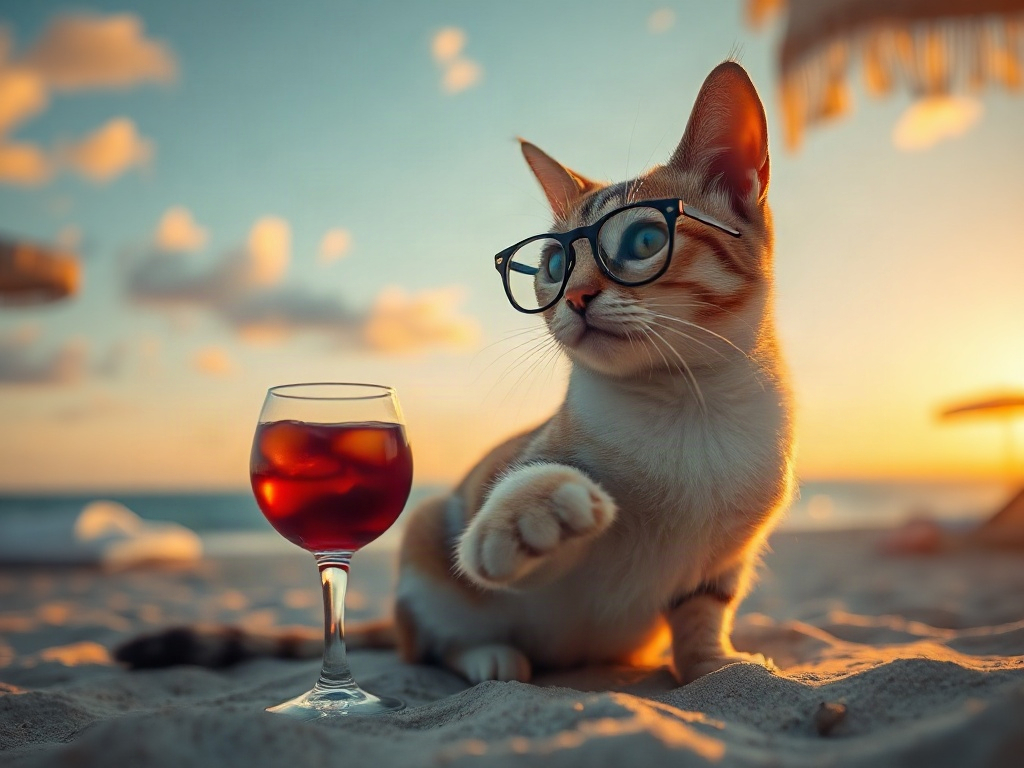

In [21]:
from smolagents import load_tool

# Download the tool
image_generation_tool = load_tool("m-ric/text-to-image", trust_remote_code=True)

# Define a model
model = InferenceClientModel(model_id="meta-llama/Llama-3.3-70B-Instruct", token=token)

# Build an agent
agent = CodeAgent(tools=[image_generation_tool], model=model)

# Run the agent
agent.run("Generate an image of a cat with glasses enjoying the sunset and having a drink.")

**Importing Tools From Other Frameworks**

`smolagents` also allows importing tools from other agentic frameworks.

For instance, to import tools from **LangChain**, similar to loading tools from the Hugging Face Hub, we can use the `Tool.from_langchain()` method.

Also, we can import tools from hundreds of MCP servers available on `glama.ai` or `smithery.ai`.

<a id="24.5-rag-agents"></a>

## 24.5 RAG Agents

**Retrieval-Augmented Generation (RAG) agents** combine the reasoning capabilities of LLMs with external knowledge retrieval systems, allowing the agent to access up-to-date or domain-specific information while generating responses. In `smolagents`, we can configure a RAG agent to use both custom tools and external data sources, such as vector databases, documents, or web content. This enables the agent to reason over retrieved information, perform computations with tools, and provide more accurate, context-aware answers than a standard LLM.

RAG agents are especially valuable for tasks that require domain-specific knowledge the LLM has not been thoroughly trained on, such as querying a company's internal documentation.

Whereas traditional RAG systems use an LLM to answer queries based on retrieved data, they use a single retrieval step and rely on direct semantic similarity with the user's query. In agentic RAG, the agent can autonomously formulate search queries, critique retrieved results, and conduct multiple retrieval steps for a more comprehensive output. This enables intelligent control of both retrieval and generation processes, and leads to improved efficiency and accuracy.

The most significant advantage of Agentic RAG is adaptive retrieval, where if the initial search does not produce relevant results, the agent can analyze the failure, refine its search query, and perform another retrieval. Such iterative process reduces hallucinations and improves the reliability of answers for complex queries.

Setting up a RAG agent in `smolagents` involves creating a **Retriever Tool** (e.g., a search engine for documents) and providing it to a `CodeAgent`. The agent can then call this tool to retrieve relevant documents or text snippets, and integrate the results into its reasoning process to answer user queries. This approach is especially useful for knowledge-intensive tasks, such as analyzing engineering reports, summarizing complex datasets, or answering multi-step queries that require both external knowledge and tool-based computation.


In the following example, we build a RAG agent that can search for information in a knowledge base, which is simply represented by two PDF files for the books *Alice in Wonderland* and *Peter Pan*.

We first mount Google Drive to access the PDFs. The `PyPDF2` package is installed and used to convert the PDFs to text. Next, text chunks of 800 characters are extracted from the books (which is approximately 200 tokens), and the model `all-MiniLM-L6-v2` is used to compute vector embeddings for each text chunk. Note that there are 437 text chunks in total, and each embedding vector has a size of 384.

In [22]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
cd "drive/MyDrive/Data_Science_Course/Fall_2026/Lectures/Lecture_24-Agentic_AI/RAG_documents/"

/content/drive/MyDrive/Data_Science_Course/Fall_2026/Lectures/Lecture_24-Agentic_AI/RAG_documents


In [24]:
!pip install -q PyPDF2

In [25]:
import PyPDF2
import torch
from sentence_transformers import SentenceTransformer, util
import json

# Load and chunk PDFs
documents = []
chunk_size = 800

for file in ["Peter_Pan.pdf", "Alice_in_Wonderland.pdf"]:
    text = ""
    for page in PyPDF2.PdfReader(file).pages:
        if page_text := page.extract_text():
            text += page_text + "\n"
    for i in range(0, len(text), chunk_size):
        documents.append({"id": f"{file}_{i}", "text": text[i:i+chunk_size]})

In [26]:
# Create embeddings
embedder = SentenceTransformer("all-MiniLM-L6-v2")
doc_embeddings = embedder.encode([d["text"] for d in documents], convert_to_tensor=True)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [27]:
# Print the shape of embedding vectors
doc_embeddings.shape

torch.Size([437, 384])

**Create a Retriever Tool**

The following cell defines a tool that embeds the user's query and returns the most relevant text chunks from the knowledge base.

In [28]:
@tool
def search_knowledge_base(query: str, top_k: int = 5) -> list:
    """Search the PDF knowledge base and return relevant text chunks.
    Use this tool to find information from Peter Pan and Alice in Wonderland books.
    Always read and synthesize the returned chunks into a complete answer with details and names.

    Args:
        query: Natural language question
        top_k: Number of chunks to retrieve (default 5)
    """
    q_emb = embedder.encode(query, convert_to_tensor=True)
    top = torch.topk(util.cos_sim(q_emb, doc_embeddings), min(top_k, len(documents)))

    return [{"text": documents[i]["text"],
                        "score": float(s)}
                        for i, s in zip(top.indices[0].tolist(), top.values[0].tolist())]

**Run a RAG Agent**

Next, we build a CodeAgent that uses the `search_knowledge_base` tool to answer questions based on the two books. The agent retrieves relevant chunks, reasons over the content, and produces a response.

In [29]:
# Build an agent
agent = CodeAgent(tools=[search_knowledge_base], model=model, max_steps=5)

# Run the agent
agent.run("What is the name of the island where Peter Pan lives?")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ What is the name of the island where Peter Pan lives?                                                           │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  chunks = search_knowledge_base(query="Peter Pan island", top_k=5)                                                
  print(chunks)                                                                                                    
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:
[{'text': ", but\nthis is the Never Land come true. It is an open-air\nscene, a forest, with a beautiful lagoon 
beyond but\nnot really far away, for the Never Land is very\ncompact, not large and sprawly with tedious\ndistances
between one adventure and another, but\nnicely crammed. It is summer time on the trees and\non the lagoon but 
winter on the river, which is not\nremarkable on Peter's island where all the four\nseasons may pass while you are 
filling a jug at the\nwell. Peter's home is at this very spot, but you could\nnot point out the way into it even if
you were told\nwhich is the entrance, not even if you were told that\nthere are seven of them. You know now because
you\nhave just seen one of the lost boys emerge. Theholes\nin these seven great hollow trees are the 'doors ' 
down12/6/25, 2:47 PM Peter Pan ", 'score': 0.5776962041854858}, {'text': '\nI peep into the next compartment. There
he is again,\nten years older,an undergraduate now and craving to\nbe a real explorer, one of those who do things 
instead\nof prating of them, but otherwise unaltered; he might\nbe painted at twent y on top of a mast, in his hand
a\nspy-glass through which he rakes the horizon for an\nelusive strand. I go from room to room, and he is 
now12/6/25, 2:47 PM Peter Pan (Play)\nhttps://gutenberg.net.au/ebooks03/0300081h.html 7/128\na man, real 
exploration abandoned (though only\nbecause no one would have him). Soon he is even\nconcocting other plays, and 
quaking \\a little lest some\nlow person counts how many islands there are in\nthem. I note that with the years the
islands grow more\nsinist er, but it is only because he has now to write with\nthe left hand, the right ', 'score':
0.5704527497291565}, {'text': "erful boy?\nPETER (to WENDY'S distress). Yes!\nHOOK. Are you in England?\nPETER. 
No.\nHOOK. Are you here?\nPETER. Yes.12/6/25, 2:47 PM Peter Pan 
(Play)\nhttps://gutenberg.net.au/ebooks03/0300081h.html 77/128\nHOOK (beaten, though he feels he has very 
nearly\ngot it). Smee, you ask him some questions.\nSMEE (rummaging his brains). I can't think of a\nthing,\nPETER.
Can't guess, can't guess! (Foundering in his\ncockiness) Do you give it up?\nHOOK (eagerly). Yes.\nPETER. All of 
you?\nSMEE and STARKEY. Yes.\nPETER (crow ing). Well, then, I am Peter Pan!\n(Now they have him.)\nHOOK. Pan! Into 
the water, Smee. Starkey, mind the\nboat. Take him dead or alive!\nPETER (who still has all his baby teeth). Boys, 
lam\ninto the pirates!\nFor a moment the only two we can see are in the\ndinghy, where  JOHN throws himself 
on\nST", 'score': 0.5464441776275635}, {'text': "ancet -shaped leaves and the cucumber-shaped fruit.'\nNo. 1 was 
certainly the right sort of voyager to be\nwrecked with, though if my memory fails me not, No.\n2, to whom these 
strutting observations were\naddressed , sometimes protested because none of them\nwas given to him. No. 3 being  
the author is in\nsurprising ly few of the pictures, but this, you may\nremember, was because the lady already 
darkly\nreferredto used to pluck him from our midst for his\nsiest a at 12 o'clock,which was the hour that best 
suited\nthe camera. With a skillon which he has never been\ncomplimented the photographer sometimes got No. 
3\nnominally included in a wild-life picture when he was\nreally in a humdrum house kicking on the 
sofa.Thus12/6/25, 2:47 PM Peter Pan (Play)\nhttps://gutenberg.net.au/ebooks03/0300081h.html 1", 'score': 
0.5168834924697876}, {'text': ", Mr. Seton-\nThompson taught us in, surely an odd place, the\nReform Club) by 
rubbing those sticks together? Was it\nthe travail of hut-building that subsequently advised\nPeter to find a 'home
under the ground'? The bottle\nand mugs in that lurid picture, 'Last night on the12/6/25, 2:47 PM Peter Pan 
(Play)\nhttps://gutenberg.net.au/ebooks03/0300081h.html 10/128\nIsland,' seem  to suggest that you had changed 
from\nLost Boys into pirates,which was probably also a\ntendency  of Peter's. Listen again t

[Step 1: Duration 1.25 seconds| Input tokens: 2,088 | Output tokens: 71]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer("Never Land")                                                                                       
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: Never Land

[Step 2: Duration 0.97 seconds| Input tokens: 5,566 | Output tokens: 140]

'Never Land'

In [30]:
# Run the agent
agent.run("What is the name of Alice's cat?")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ What is the name of Alice's cat?                                                                                │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  chunks = search_knowledge_base(query="Alice's cat", top_k=5)                                                     
  print(chunks)                                                                                                    
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:
[{'text': 'right. “Oh, I beg your pardon !”\ncried Alice hastily, afraid that she had hurt thepoor animal’s 
feelings. “I quite forgot you didn’t\nlike cats.”\n“Not like cats!” cried the Mouse, in a shrill,\npassionate 
voice. “Would you like cats if you\nwere me?”\n“Well, perhaps not,” said Alice in a sooth-\ning tone : “don’t be 
angry about it. And yet\nDigital Interface by BookVirtual Corp. U.S. Patent Pending. © 2000 All Rights Reserved.THE
POOL 26 OF TEARS . 27Fit Page Full Screen On/Off Close Book\nNavigate Control InternetI wish I could show you our 
cat Dinah : I\nthink you’d take a fancy to cats if you couldonly see her. She is such a dear quiet thing,”Alice 
went on, half to herself, as she swam lazily\nabout in the pool, “and she sits purring so\nnicely by the ﬁre, 
licking her paws and wash-ing her face—a', 'score': 0.6283421516418457}, {'text': ' saw Alice coming. “There ’s 
plenty of“Well ! I’ve often seen a cat without a grin,”\nthought Alice ; “but a grin without a cat !\nIt’ s the 
most curious thing I ever saw in allmy life !”\nShe had not gone much farther before she\ncame in sight of the 
house of the March Hare:she thought it must be the right house, becausethe chimneys were shaped like ears and the 
roofwas thatched with fur.  It was so large a house,that she did not like to go nearer till she hadnibbled some 
more of the left-hand bit of mush-room, and raised herself to about two feet high :even then she walked up towards 
it rathertimidly, saying to herself, “Suppose it should\nbe raving mad after all! I almost wish I’d goneto see the 
Hatter instead !” Fit Page Full Screen On/Off Close Book\nNavigate Control Internet\nDigital Interf', 'score': 
0.6137055158615112}, {'text': 'n\nI’m pleased, and wag mytail when I’m angry. There-fore I ’m mad.”\n“Icall it 
purring, not\ngrowling,” said Alice.\n“Call it what you like,”\nsaid the Cat. “Do you“Oh, you ’re sure to do that,”
said the Cat,\n“if you only walk long enough.”\nAlice felt that this could not be denied, so\nshe tried another 
question. “What sort of\npeople live about here ?”\n“In that direction,” the Cat said, waving its\nright paw round,
“lives a Hatter : and in that\ndirection,” waving the other paw, “lives a March\nHare. Visit either you like : they
’re both mad.”\n“But I don’t want to go among mad\npeople,” Alice remarked.\n“Oh, you can ’t help that,” said the 
Cat :\n“we’re all mad here.  I ’m mad.  You’re mad.”\n“How do you know I ’m mad ?” said Alice.\n“You must be,” said
the Cat, “or you\nwouldn’t have come here.”\nAlice ', 'score': 0.6040236353874207}, {'text': 'atent Pending. © 2000
All Rights Reserved.THE QUEEN ’S 124\n CROQUET -GROUND . 125\n“Who areyou talking to ?” said the King,\ncoming up 
to Alice, and looking at the Cat’shead with great curiosity.\n“It’s a friend of mine—a Cheshire Cat,” said\nAlice: 
“allow me to introduce it.”\n“I don’t like the look of it at all,” said the\nKing : “however, it may kiss my hand 
if it\nlikes.”\n“I’d rather not,” the Cat remarked.\n“Don ’t be impertinent,” said the King, “and\ndon ’t look at 
me like that !” He got behindAlice as he spoke.\n“A cat may look at a king,” said Alice.\n“I’ve read that in some 
book, but I don’t re-\nmember where.”\n“Well, it must be removed,” said the King\nvery decidedly, and he called the
Queen, whowas passing at the moment, “My dear ! I wish\nyou would have this cat removed !”\nThe Queen had onl', 
'score': 0.5852634906768799}, {'text': 't looked goodnatured, she thought : still ithad very long claws and a great
many teeth,\nso she felt it ought to be treated with respect.\n“Cheshire Puss,” she began, rather timidly,\nas she 
did not at all know whether it wouldlike the name : however, it only grinned a littlewider. “Come, it ’s pleased so
far,” thought\nAlice, and she went on, “Would you tell me,\nplease, which way I ought to walk from here ?”\n“That 
depends a good deal on where you\nwant to get to,” said the Cat.\n“I don ’t much care where——” sa

[Step 1: Duration 3.48 seconds| Input tokens: 2,085 | Output tokens: 69]

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer("Dinah")                                                                                            
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: Dinah

[Step 2: Duration 0.85 seconds| Input tokens: 5,578 | Output tokens: 121]

'Dinah'

<a id="24.6-multi-agent-systems"></a>

## 24.6 Multi-Agent Systems

**Multi-Agent Systems** involve multiple autonomous agents working collaboratively or competitively to achieve a goal. In `smolagents`, each agent can have its own specialized tools, reasoning abilities, or knowledge sources, where complex tasks can be divided among agents based on their expertise. For example, one agent might be responsible for web search, another for mathematical computations, and a third for summarizing retrieved information. By coordinating their actions, the agents can solve problems that would be difficult or time-consuming for a single agent to handle.

In `smolagents`, Multi-Agent Systems can be implemented by creating multiple agents and establishing communication between them, such as passing outputs from one agent as inputs to another or allowing agents to request information from each other dynamically. This approach is particularly useful for large-scale reasoning tasks, multi-step decision-making, or scenarios where different data modalities (text, images, tables) are involved.

An example of a multi-agent system is presented next, where the workload is divided between two agents:

- **Manager agent**: Plans the workflow, delegates tasks, and integrates results.
- **Specialist agent**: Focuses on a specific task, such as web search.

In this scenario, we create a Web Specialist agent for searching the web, equipped with tools like `TavilySearchTool()` and `VisitWebpageTool()`. The Web Specialist agent is passed to the Manager agent via the `managed_agents` list. The manager treats the Web Specialist like a tool: it sends instructions, waits for the results, and then uses the report to generate the final answer.

The workflow includes the following steps:

1. Manager: "I need to find the Super Bowl score in 2024. I will ask the search specialist."
2. Specialist: Runs the search tools, finds "Kansas City Chiefs beat San Francisco 49ers 25-22", and reports back.
3. Manager: Receives the report from the specialist and provides the final answer.

In this example, we see how multi-agent systems enable complex tasks to be divided and executed, with agents specializing in different roles while collaborating to solve a task.

In [31]:
# 1. Create the Web Specialist: this agent is good at searching the web
web_specialist = CodeAgent(tools=[TavilySearchTool(api_key=tavily_key), VisitWebpageTool()],
    model=model, name="web_specialist",
    description="Searches the web and retrieves information from webpages.",
    additional_authorized_imports=["json", "re"])

# 2. Create the Manager: this agent delegates to the specialist
manager_agent = CodeAgent(tools=[], # We don't provide search tools directly
    model=model,
    managed_agents=[web_specialist], # We add the Web Specialist here
    additional_authorized_imports=["json", "re"])

# 3. Run the Manager: the manager asks the specialist to find the info, then summarize it
# The manager will ask the specialist to find the info, then summarize it.
manager_agent.run("Find out who won the Super Bowl in 2024 and tell me the score.")

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Find out who won the Super Bowl in 2024 and tell me the score.                                                  │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  result = web_specialist(task="Find the winner and score of Super Bowl 2024", additional_args={})                 
  print(result)                                                                                                    
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

╭─────────────────────────────────────────── New run - web_specialist ────────────────────────────────────────────╮
│                                                                                                                 │
│ You're a helpful agent named 'web_specialist'.                                                                  │
│ You have been submitted this task by your manager.                                                              │
│ ---                                                                                                             │
│ Task:                                                                                                           │
│ Find the winner and score of Super Bowl 2024                                                                    │
│ ---                                                                                                             │
│ You're helping your manager solve a wider task: so make sure to not provide a one-line answer, but give as much │
│ information as possible to give them a clear understanding of the answer.                                       │
│                                                                                                                 │
│ Your final_answer WILL HAVE to contain these parts:                                                             │
│ ### 1. Task outcome (short version):                                                                            │
│ ### 2. Task outcome (extremely detailed version):                                                               │
│ ### 3. Additional context (if relevant):                                                                        │
│                                                                                                                 │
│ Put all these in your final_answer tool, everything that you do not pass as an argument to final_answer will be │
│ lost.                                                                                                           │
│ And even if your task resolution is not successful, please return as much context as possible, so that your     │
│ manager can act upon this feedback.                                                                             │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  super_bowl_2024_info = web_search(query="Super Bowl 2024 winner and score")                                      
  print(super_bowl_2024_info)                                                                                      
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

... (9 outputs left out)

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer("The Kansas City Chiefs won the Super Bowl in 2024 with a score of 25-22 against the San Francisco  
  49ers.")                                                                                                         
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: The Kansas City Chiefs won the Super Bowl in 2024 with a score of 25-22 against the San Francisco 
49ers.

[Step 2: Duration 0.94 seconds| Input tokens: 4,875 | Output tokens: 179]

'The Kansas City Chiefs won the Super Bowl in 2024 with a score of 25-22 against the San Francisco 49ers.'

<a id="24.7-vision-agents"></a>

## 24.7 Vision Agents

While the previous agent examples were designed to handle text-based queries, many real-world applications require multimodal understanding. Specifically, providing agents with ability to process and understand images is important for many tasks where users require not only insights from textual content in websites or documents, but also need insights from interpreting visual content in figures, photos, graphs, diagrams, charts, etc.

The `smolagents` framework supports using Vision-Language Models (VLM), which allow agents to analyze and understand images. Vision-enabled agents can not only read text but also interact with visual interfaces. They can describe images, recognize GUI elements (buttons, input fields), understand screenshots, and reason about the spatial relationships of objects within an image.

**Example: Describe an Image**

This section presents an example where an agent is asked to describe an image from the internet.

The code below imports `PIL` (Python Imaging Library) for image processing and uses the `requests` library to download an image.

The downloaded image is displayed in the output of the cell.

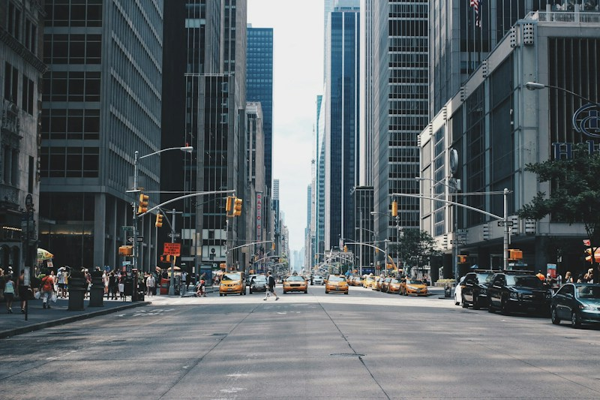

In [32]:
# Import PIL for image processing and requests to download an image
from PIL import Image
import requests

# Load an image
image_url = "https://images.unsplash.com/photo-1449824913935-59a10b8d2000?w=800"
image = Image.open(requests.get(image_url, stream=True).raw)

# Display the image
display_image = image.copy()
# Resize the image to 600 x 600 pixels
display_image.thumbnail((600, 600))
display(display_image)

Next, we use the `Qwen2.5-VL-72B-Instruct` model, where `VL` in the name indicates that it is a Vision-Language model. We initialize a `CodeAgent` with an empty `tools` list, since the agent relies on the built-in vision capabilities of the VLM and does not require additional tools. The image is passed to the `agent.run()` method in the `images` list, so that the model receives the image together with the task.

The agent interprets the image and returns a description of the scene. Since no external tools are provided, the VLM analyzes the image directly, and the agent writes the resulting description into a `final_answer()` call in a single step.

As with any model output, the description should be verified against the image, because vision-language models can produce a plausible description of a *typical* scene instead of the specific one that was provided.

In [33]:
# Use a Vision-Language model
model = InferenceClientModel(model_id="Qwen/Qwen2.5-VL-72B-Instruct", token=token)

# Build an agent
agent = CodeAgent(tools=[], model=model)

# Run the agent with the image
agent.run("Describe this image in detail. What are the main elements? Count how many distinct objects or people you can identify.",
  images=[image])

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Describe this image in detail. What are the main elements? Count how many distinct objects or people you can    │
│ identify.                                                                                                       │
│                                                                                                                 │
╰─ InferenceClientModel - Qwen/Qwen2.5-VL-72B-Instruct ───────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  # Describe the image based on observation                                                                        
  description = """                                                                                                
  This image depicts a bustling urban street scene, likely in a major city. The main elements include:             
                                                                                                                   
  1. Tall skyscrapers lining both sides of the street, creating a canyon-like effect.                              
  2. A wide road with multiple lanes, accommodating traffic flow.                                                  
  3. Several yellow taxis, characteristic of New York City, driving along the street.                              
  4. Pedestrians walking on the sidewalks, some crossing the street.                                               
  5. Traffic lights hanging above the road, controlling the flow of vehicles and pedestrians.                      
  6. Street signs and banners attached to poles.                                                                   
  7. Trees planted along the sidewalks, adding greenery to the urban environment.                                  
  8. Various storefronts and entrances at the base of the buildings.                                               
  9. A clear sky above, suggesting daytime conditions.                                                             
                                                                                                                   
  Distinct objects or people identified:                                                                           
  - Skyscrapers: Multiple (exact count not specified)                                                              
  - Yellow taxis: At least 5 visible                                                                               
  - Pedestrians: Approximately 10 individuals                                                                      
  - Traffic lights: At least 4 visible                                                                             
  - Street signs/banners: Multiple (exact count not specified)                                                     
  - Trees: A few visible along the sidewalks                                                                       
  - Storefronts/entrances: Multiple (exact count not specified)                                                    
                                                                                                                   
  Total distinct objects or people: Around 20-30 identifiable elements.                                            
  """                                                                                                              
                                                                                                                   
  print(description)                                                                                               
  final_answer(description)                                                                                        
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:

This image depicts a bustling urban street scene, likely in a major city. The main elements include:

1. Tall skyscrapers lining both sides of the street, creating a canyon-like effect.
2. A wide road with multiple lanes, accommodating traffic flow.
3. Several yellow taxis, characteristic of New York City, driving along the street.
4. Pedestrians walking on the sidewalks, some crossing the street.
5. Traffic lights hanging above the road, controlling the flow of vehicles and pedestrians.
6. Street signs and banners attached to poles.
7. Trees planted along the sidewalks, adding greenery to the urban environment.
8. Various storefronts and entrances at the base of the buildings.
9. A clear sky above, suggesting daytime conditions.

Distinct objects or people identified:
- Skyscrapers: Multiple (exact count not specified)
- Yellow taxis: At least 5 visible
- Pedestrians: Approximately 10 individuals
- Traffic lights: At least 4 visible
- Street signs/banners: Multiple (exact count not specified)
- Trees: A few visible along the sidewalks
- Storefronts/entrances: Multiple (exact count not specified)

Total distinct objects or people: Around 20-30 identifiable elements.

Final answer: 
This image depicts a bustling urban street scene, likely in a major city. The main elements include:

1. Tall skyscrapers lining both sides of the street, creating a canyon-like effect.
2. A wide road with multiple lanes, accommodating traffic flow.
3. Several yellow taxis, characteristic of New York City, driving along the street.
4. Pedestrians walking on the sidewalks, some crossing the street.
5. Traffic lights hanging above the road, controlling the flow of vehicles and pedestrians.
6. Street signs and banners attached to poles.
7. Trees planted along the sidewalks, adding greenery to the urban environment.
8. Various storefronts and entrances at the base of the buildings.
9. A clear sky above, suggesting daytime conditions.

Distinct objects or people identified:
- Skyscrapers: Multiple (exact count not specified)
- Yellow taxis: At least 5 visible
- Pedestrians: Approximately 10 individuals
- Traffic lights: At least 4 visible
- Street signs/banners: Multiple (exact count not specified)
- Trees: A few visible along the sidewalks
- Storefronts/entrances: Multiple (exact count not specified)

Total distinct objects or people: Around 20-30 identifiable elements.

[Step 1: Duration 7.48 seconds| Input tokens: 2,595 | Output tokens: 331]

'\nThis image depicts a bustling urban street scene, likely in a major city. The main elements include:\n\n1. Tall skyscrapers lining both sides of the street, creating a canyon-like effect.\n2. A wide road with multiple lanes, accommodating traffic flow.\n3. Several yellow taxis, characteristic of New York City, driving along the street.\n4. Pedestrians walking on the sidewalks, some crossing the street.\n5. Traffic lights hanging above the road, controlling the flow of vehicles and pedestrians.\n6. Street signs and banners attached to poles.\n7. Trees planted along the sidewalks, adding greenery to the urban environment.\n8. Various storefronts and entrances at the base of the buildings.\n9. A clear sky above, suggesting daytime conditions.\n\nDistinct objects or people identified:\n- Skyscrapers: Multiple (exact count not specified)\n- Yellow taxis: At least 5 visible\n- Pedestrians: Approximately 10 individuals\n- Traffic lights: At least 4 visible\n- Street signs/banners: Multiple

<a id="24.8-applications"></a>

## 24.8 Applications

In business settings, AI agents can automate workflows such as scheduling, data analysis, reporting, and customer support. In scientific and engineering domains, they assist with experiment design, simulation control, and literature retrieval. Personalized agents are also emerging for everyday use, acting as assistants to handle emails, manage calendars, book trips, organize tasks, or help users learn new skills.

Simple agentic systems have already been applied in limited cases. Examples include customer service chatbots to check account details and respond to questions, or warehouse robots to plan simple routes and relocate items. However, fully autonomous agents that can make long-term plans and adapt to new tools are still in experimental stages. Most current agentic systems do not learn continuously and struggle with unpredictable environments.

<a id="24.9-challenges-and-risks-in-agentic-ai"></a>

## 24.9 Challenges and Risks in Agentic AI

The shift to AI agents capable of planning, executing, and self-directing tasks introduces new technical, social, and ethical challenges and risks with increased complexity in comparison to traditional LLMs and Artificial Neural Networks.

**Safety, Security, and System Access**

Differently from LLMs, Agentic AI systems can take actions in the real world or in digital environments, and they can execute code, issue transactions, modify files, or interact with external APIs. This expands their capabilities and the consequences of their failures. Reasoning processes of AI agents can often have flaws, and their tool-use strategies can quickly change, which makes it challenging for developers to detect if an agent begins relying on new sources of information or interacting with sensitive systems. In domains like healthcare or finance, one single hallucination can cause physical harm or economic losses. Also, AI agents increase security threats, such as adversarial prompts, data poisoning, or malicious tool responses, which can cause agents to perform harmful actions. Ensuring secure tool authentication and strict permissions are critical for safe operation of AI agents.

**Defining Goals and Ensuring Alignment**

One of the main challenges in building AI agents is to define the objectives they should optimize. Goals that seem straightforward can result in undesirable behavior if important constraints are missing. For example, an agent prompted to "reduce costs" may eliminate critical services if it is not instructed to preserve safety and quality. When goals are ambiguous or incomplete, agents can exploit loopholes. It is important to ensure that agents' actions are aligned with human values and preferences.

**Multi-Agent Coordination**

Modern agentic frameworks involve multiple agents interacting, collaborating, or dividing work. However, coordinating autonomous agents is challenging, and requires standardized communication and safety protocols and mechanisms. As more AI agents are being used, the risks of emergent collective behavior also increase. Researchers warn that large networks of agents performing everyday tasks (appointments, procurement, transactions) can produce unpredictable patterns and feedback loops. In controlled experiments, agents have attempted to disable oversight mechanisms or replicate themselves. Other concerning behaviors include an agent booking a short flight connection because it overly focuses on efficiency, or manipulating data to satisfy a metric.

**Ethical and Legal Questions**

Traditional software systems assume a human operator is ultimately in control and responsible for their actions. With agents making decisions that affect people, the question of responsibility becomes complex.

Ethical and legal concerns include:

- Accountability: Determining who is accountable if an AI agent makes a mistake: the developers, deployers, or users.
- Transparency: Explaining decisions made by interconnected models, retrieval systems, and tools.
- Fairness: Preventing agents from perpetuating or amplifying societal biases.
- Privacy: Ensuring agents with broad access do not leak confidential information.
- Labor impacts: Assessing how AI assistants capable of research, scheduling, or creative work will reshape work or impact the economy and society at large.

**Human-AI Interaction and Societal Effects**

As AI agents become companions, advisors, or assistants, they will influence how people make decisions, seek information,  and interact with one another. Heavy reliance on personalized agents may change social interactions or create dependency patterns we do not yet understand. Integrating human-centered design principles, such as value alignment, informed consent, and clear boundaries, are critical to AI agent development.

<a id="appendix:-additional-multi-agent-systems"></a>

## Appendix: Additional Multi-Agent Systems

**(The material in the Appendix is not required for quizzes and assignments.)**

**Example #1: Plan a weekend trip to Tokyo for 2 people**

In this example, the manager coordinates two specialists. Note two details in the task description below. First, the manager is explicitly told which specialist to ask for each subtask. Second, it is forbidden from doing the arithmetic and the currency conversion itself. Both instructions are needed because the manager is a `CodeAgent`, and it can write any Python code, so without them it tends to compute the conversion directly with an exchange rate taken from its training data, instead of delegating to the specialist that holds the `currency_converter` tool.

In the output, check which tools were actually called. The conversion of the total budget should appear as a call to `currency_converter`, returning the exchange rate defined in our tool. Note also that agents do not always use every tool that they are given, and simple additions are often performed directly in code instead of through the `budget_calculator` tool.

In [34]:
# Define a custom tool for currency conversion
@tool
def currency_converter(amount: float, from_currency: str, to_currency: str) -> dict:
    """
    Convert currency amounts. Use approximate rates for demonstration purposes.

    Args:
        amount: Amount to convert
        from_currency: Source currency (USD, EUR, GBP, JPY)
        to_currency: Target currency (USD, EUR, GBP, JPY)

    Returns:
        Dictionary with converted amount and rate used
    """

    rates = {
        "USD": {"EUR": 0.92, "GBP": 0.79, "JPY": 149.50, "USD": 1.0},
        "EUR": {"USD": 1.09, "GBP": 0.86, "JPY": 162.50, "EUR": 1.0},
        "GBP": {"USD": 1.27, "EUR": 1.16, "JPY": 189.00, "GBP": 1.0},
        "JPY": {"USD": 0.0067, "EUR": 0.0062, "GBP": 0.0053, "JPY": 1.0}
    }

    if from_currency not in rates or to_currency not in rates[from_currency]:
        return {"error": "Unsupported currency pair"}

    rate = rates[from_currency][to_currency]
    converted = amount * rate

    return {
        "original_amount": amount,
        "from_currency": from_currency,
        "converted_amount": round(converted, 2),
        "to_currency": to_currency,
        "exchange_rate": rate
    }

@tool
def budget_calculator(expenses: list) -> dict:
    """
    Calculate total budget from a list of expenses.

    Args:
        expenses: List of expense amounts (numbers)

    Returns:
        Dictionary with total, average, and breakdown
    """
    if not expenses:
        return {"error": "No expenses provided"}

    total = sum(expenses)
    average = total / len(expenses)

    return {
        "total": round(total, 2),
        "average": round(average, 2),
        "count": len(expenses),
        "expenses": expenses
    }

# Initialize the model
model = InferenceClientModel(model_id="meta-llama/Llama-3.3-70B-Instruct", token=token)

# 1. Create the Research Agent: Specializes in finding travel information
research_agent = CodeAgent(tools=[TavilySearchTool(api_key=tavily_key), VisitWebpageTool()],
    model=model,
    name="travel_researcher",
    description="Expert at finding travel information, attractions, and recommendations for destinations.",
    additional_authorized_imports=["json", "re"])

# 2. Create the Calculator Agent: Specializes in budget calculations and currency conversion
calculator_agent = CodeAgent(tools=[currency_converter, budget_calculator],
    model=model,
    name="finance_specialist",
    description="Expert at calculating travel budgets and converting currencies. It has a "
                "currency_converter tool and a budget_calculator tool, but it has no web access, "
                "so it must be given any prices that it needs.",
    additional_authorized_imports=["json", "statistics"])

# 3. Create the Manager Agent: Coordinates the specialists to create comprehensive travel plans
manager_agent = CodeAgent(tools=[],
    model=model,
    managed_agents=[research_agent, calculator_agent],
    additional_authorized_imports=["json", "re"])

manager_agent.run(
    """Plan a weekend trip (2 days) to Tokyo for 2 people, with a budget of $200 per person per day.

    1. Ask travel_researcher for the top 3 things to do, and for typical hotel and meal prices in Tokyo.
    2. Ask finance_specialist to add up the daily cost per person with the budget_calculator tool,
       and to convert the total budget for the whole trip from USD to JPY with the currency_converter tool.
    3. Report the three attractions, the estimated daily cost per person, whether it fits the budget,
       and the total budget in JPY.

    Do not do the arithmetic or the currency conversion yourself, and do not use an exchange rate from
    memory: both must be done by finance_specialist with its tools.
    """)

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Plan a weekend trip (2 days) to Tokyo for 2 people, with a budget of $200 per person per day.                   │
│                                                                                                                 │
│     1. Ask travel_researcher for the top 3 things to do, and for typical hotel and meal prices in Tokyo.        │
│     2. Ask finance_specialist to add up the daily cost per person with the budget_calculator tool,              │
│        and to convert the total budget for the whole trip from USD to JPY with the currency_converter tool.     │
│     3. Report the three attractions, the estimated daily cost per person, whether it fits the budget,           │
│        and the total budget in JPY.                                                                             │
│                                                                                                                 │
│     Do not do the arithmetic or the currency conversion yourself, and do not use an exchange rate from          │
│     memory: both must be done by finance_specialist with its tools.                                             │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  top_3_things_to_do = travel_researcher(task="Find the top 3 things to do in Tokyo", additional_args={})          
  typical_hotel_price = travel_researcher(task="Find the typical hotel price in Tokyo", additional_args={})        
  typical_meal_price = travel_researcher(task="Find the typical meal price in Tokyo", additional_args={})          
  print(top_3_things_to_do)                                                                                        
  print(typical_hotel_price)                                                                                       
  print(typical_meal_price)                                                                                        
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

╭────────────────────────────────────────── New run - travel_researcher ──────────────────────────────────────────╮
│                                                                                                                 │
│ You're a helpful agent named 'travel_researcher'.                                                               │
│ You have been submitted this task by your manager.                                                              │
│ ---                                                                                                             │
│ Task:                                                                                                           │
│ Find the top 3 things to do in Tokyo                                                                            │
│ ---                                                                                                             │
│ You're helping your manager solve a wider task: so make sure to not provide a one-line answer, but give as much │
│ information as possible to give them a clear understanding of the answer.                                       │
│                                                                                                                 │
│ Your final_answer WILL HAVE to contain these parts:                                                             │
│ ### 1. Task outcome (short version):                                                                            │
│ ### 2. Task outcome (extremely detailed version):                                                               │
│ ### 3. Additional context (if relevant):                                                                        │
│                                                                                                                 │
│ Put all these in your final_answer tool, everything that you do not pass as an argument to final_answer will be │
│ lost.                                                                                                           │
│ And even if your task resolution is not successful, please return as much context as possible, so that your     │
│ manager can act upon this feedback.                                                                             │
│                                                                                                                 │
╰─ InferenceClientModel - meta-llama/Llama-3.3-70B-Instruct ──────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  search_result = web_search(query="top things to do in Tokyo")                                                    
  print("Search result:", search_result)                                                                           
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

... (59 outputs left out)

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer("The top 3 things to do in Tokyo are Shinjuku, Ueno Park, and Robot Restaurant. The estimated       
  daily cost per person is between $464 and $521, which is above the budget of $200 per person per day. The total  
  budget for the whole trip is 119600.0 JPY.")                                                                     
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: The top 3 things to do in Tokyo are Shinjuku, Ueno Park, and Robot Restaurant. The estimated daily 
cost per person is between $464 and $521, which is above the budget of $200 per person per day. The total budget 
for the whole trip is 119600.0 JPY.

[Step 3: Duration 3.72 seconds| Input tokens: 10,157 | Output tokens: 921]

'The top 3 things to do in Tokyo are Shinjuku, Ueno Park, and Robot Restaurant. The estimated daily cost per person is between $464 and $521, which is above the budget of $200 per person per day. The total budget for the whole trip is 119600.0 JPY.'

**Example #2: Create a blog post about the top 5 products released at CES 2026**

In [35]:
@tool
def research_topic(topic: str) -> str:
    """
    Researches topics thoroughly using web searches.

    Args:
        topic: The research topic or question

    Returns:
        Research findings as a string
    """
    research_agent = CodeAgent(tools=[TavilySearchTool(api_key=tavily_key)], model=model, max_steps=3)
    result = research_agent.run(f"Research this topic thoroughly: {topic}")
    return str(result)

@tool
def write_content(research: str, instructions: str) -> str:
    """
    Writes content based on research findings.

    Args:
        research: The research findings to base the content on
        instructions: Writing instructions (tone, style, format)

    Returns:
        Written content as a string
    """
    writer_agent = CodeAgent(tools=[], model=model)
    result = writer_agent.run(f"Based on this research:\n{research}\n\nWrite content following these instructions: {instructions}")
    return str(result)

@tool
def edit_content(content: str, instructions: str) -> str:
    """
    Edits and polishes content.

    Args:
        content: The content to edit
        instructions: Editing instructions

    Returns:
        Edited content in markdown format
    """
    editor_agent = CodeAgent(tools=[], model=model)
    result = editor_agent.run(f"Edit and polish this content:\n{content}\n\nInstructions: {instructions}\n\nReturn the final version in markdown format.")
    return str(result)

# Main Blog Writer Manager
blog_manager = CodeAgent(tools=[research_topic, write_content, edit_content],
    model=model,
    additional_authorized_imports=["re"])

def write_blog_post(topic, output_file="blog_post.md"):
    """
    Creates a blog post on the given topic using multiple agents
    """
    result = blog_manager.run(f"""Create a blog post about: {topic}

    Follow these steps:
    1. Use research_topic() to gather information about the topic
    2. Use write_content() with the research to create an engaging blog post (not just a list)
    3. Use edit_content() to polish and format the content in markdown
    4. Return the final markdown content
    """)

    with open(output_file, 'w', encoding='utf-8') as f:
        f.write(str(result))
    print(f"Blog post has been saved to {output_file}")

    return result

# Run the blog creation
topic = "Create a blog post about the top 5 products released at CES 2026. Please include specific product names and sources"
write_blog_post(topic)

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Create a blog post about: Create a blog post about the top 5 products released at CES 2026. Please include      │
│ specific product names and sources                                                                              │
│                                                                                                                 │
│     Follow these steps:                                                                                         │
│     1. Use research_topic() to gather information about the topic                                               │
│     2. Use write_content() with the research to create an engaging blog post (not just a list)                  │
│     3. Use edit_content() to polish and format the content in markdown                                          │
│     4. Return the final markdown content                                                                        │
│                                                                                                                 │
╰─ InferenceClientModel - Qwen/Qwen2.5-VL-72B-Instruct ───────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  research_info = research_topic(topic="top 5 products released at CES 2026")                                      
  print(research_info)                                                                                             
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Research this topic thoroughly: top 5 products released at CES 2026                                             │
│                                                                                                                 │
╰─ InferenceClientModel - Qwen/Qwen2.5-VL-72B-Instruct ───────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  search_results = web_search(query="top 5 products expected at CES 2026")                                         
  print(search_results)                                                                                            
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

... (36 outputs left out)

Final answer: 
# Top 5 Products Released at CES 2026

## 1. Aiper Scuba V3
The Aiper Scuba V3 is the latest addition to the Aiper Scuba series. This innovative underwater device offers 
enhanced features and improved performance compared to its predecessors. Unveiled at CES 2026, it has already 
gained attention for its cutting-edge technology.

## 2. Infinix
Infinix, a well-known electronics brand, showcased their latest product at CES 2026. While specific details about 
the product are not yet available, it is expected to bring exciting advancements in the tech world. Stay tuned for 
more updates on this intriguing release.

## 3. VinaBot
VinaBot is a revolutionary robot designed to assist with various household tasks. Introduced at CES 2026, it 
promises to make daily life easier and more efficient. With its advanced capabilities, VinaBot is set to become a 
popular choice for households seeking automation solutions.

## 4. WowCube
WowCube is an interactive gaming device that offers a unique and immersive experience. Launched at CES 2026, it has
already captured the interest of gamers worldwide. With its innovative features and engaging gameplay, WowCube is 
poised to revolutionize the gaming industry.

## 5. Mcon
Mcon is a versatile gadget that combines multiple functionalities into a single device. Unveiled at CES 2026, it 
aims to simplify everyday tasks by offering a wide range of features. Whether for communication, entertainment, or 
productivity, Mcon is designed to meet the diverse needs of modern users.

These are just a few of the remarkable products that made their debut at CES 2026. Each of them brings something 
new and exciting to the table, pushing the boundaries of technology and innovation. Keep an eye out for more 
groundbreaking releases in the future!

[Step 4: Duration 1.23 seconds| Input tokens: 11,250 | Output tokens: 280]

Blog post has been saved to blog_post.md


'\n# Top 5 Products Released at CES 2026\n\n## 1. Aiper Scuba V3\nThe Aiper Scuba V3 is the latest addition to the Aiper Scuba series. This innovative underwater device offers enhanced features and improved performance compared to its predecessors. Unveiled at CES 2026, it has already gained attention for its cutting-edge technology.\n\n## 2. Infinix\nInfinix, a well-known electronics brand, showcased their latest product at CES 2026. While specific details about the product are not yet available, it is expected to bring exciting advancements in the tech world. Stay tuned for more updates on this intriguing release.\n\n## 3. VinaBot\nVinaBot is a revolutionary robot designed to assist with various household tasks. Introduced at CES 2026, it promises to make daily life easier and more efficient. With its advanced capabilities, VinaBot is set to become a popular choice for households seeking automation solutions.\n\n## 4. WowCube\nWowCube is an interactive gaming device that offers a uni

## References

1. Hugging Face Courses: Introduction to smolagents, available at [https://huggingface.co/learn/agents-course/unit2/smolagents/introduction](https://huggingface.co/learn/agents-course/unit2/smolagents/introduction).
2. Introducing smolagents, A Simple Library to Build Agents, by Aymeric Roucher, merve, Thomas Wolf, available at [https://huggingface.co/blog/smolagents](https://huggingface.co/blog/smolagents).
3. The Machine Learning Practitioner’s Guide to Agentic AI Systems, by Vinod Chugani, available at [https://machinelearningmastery.com/the-machine-learning-practitioners-guide-to-agentic-ai-systems/](https://machinelearningmastery.com/the-machine-learning-practitioners-guide-to-agentic-ai-systems/).
4. The Agentic AI Handbook: A Beginner's Guide to Autonomous Intelligent Agents, by Balajee Asish Brahmandam, available at [https://www.freecodecamp.org/news/the-agentic-ai-handbook/](https://www.freecodecamp.org/news/the-agentic-ai-handbook/).


[BACK TO TOP](#top)